# 02 — Linear baseline

Loads the **actual** Part 2 experiment JSON for `LinearBaseline`.
Training lives in `scripts/train.py` and `ml/engine/`; this notebook does not retrain.

Architecture: 8×8 global average pool + two-layer MLP, 3 logits. No convolutions.


In [1]:
from pathlib import Path
import json
from IPython.display import Image, display

from ml.engine.experiment_log import load_experiment_record
from ml.models import LinearBaseline

ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parent
rec = load_experiment_record(ROOT / "reports" / "experiments", "baseline")
print("experiment_id:", rec["experiment_id"])
print("device:", rec["device"], "amp:", rec["amp"])
print("optimizer:", rec["optimizer"], "lr:", rec["learning_rate"], "wd:", rec["weight_decay"])
print("batch_size:", rec["batch_size"], "class_weights:", rec["class_weight_usage"])
print("seconds:", round(rec["training_seconds"], 1))
print("params:", sum(p.numel() for p in LinearBaseline().parameters()))


experiment_id: baseline_20260917T192440Z
device: cuda amp: True
optimizer: adamw lr: 0.001 wd: 0.0001
batch_size: 128 class_weights: True
seconds: 1357.3
params: 12547


In [2]:
vm, tm = rec["val_metrics"], rec["test_metrics"]
print("VAL  acc={:.4f}  macro-F1={:.4f}  mild F1={:.4f}".format(
    vm["accuracy"], vm["macro_f1"], vm["per_class"]["mild"]["f1"]))
print("TEST acc={:.4f}  macro-F1={:.4f}  mild F1={:.4f}".format(
    tm["accuracy"], tm["macro_f1"], tm["per_class"]["mild"]["f1"]))
print(json.dumps(vm["per_class"], indent=2))


VAL  acc=0.4953  macro-F1=0.4374  mild F1=0.2111
TEST acc=0.5358  macro-F1=0.4391  mild F1=0.1852
{
  "little_or_none": {
    "precision": 0.7894291754756871,
    "recall": 0.5178918169209431,
    "f1": 0.6254606365159129,
    "support": 3605
  },
  "mild": {
    "precision": 0.14662921348314606,
    "recall": 0.37662337662337664,
    "f1": 0.21107966033158107,
    "support": 693
  },
  "severe": {
    "precision": 0.45738779626828036,
    "recall": 0.49562841530054647,
    "f1": 0.4757408864411225,
    "support": 1830
  }
}


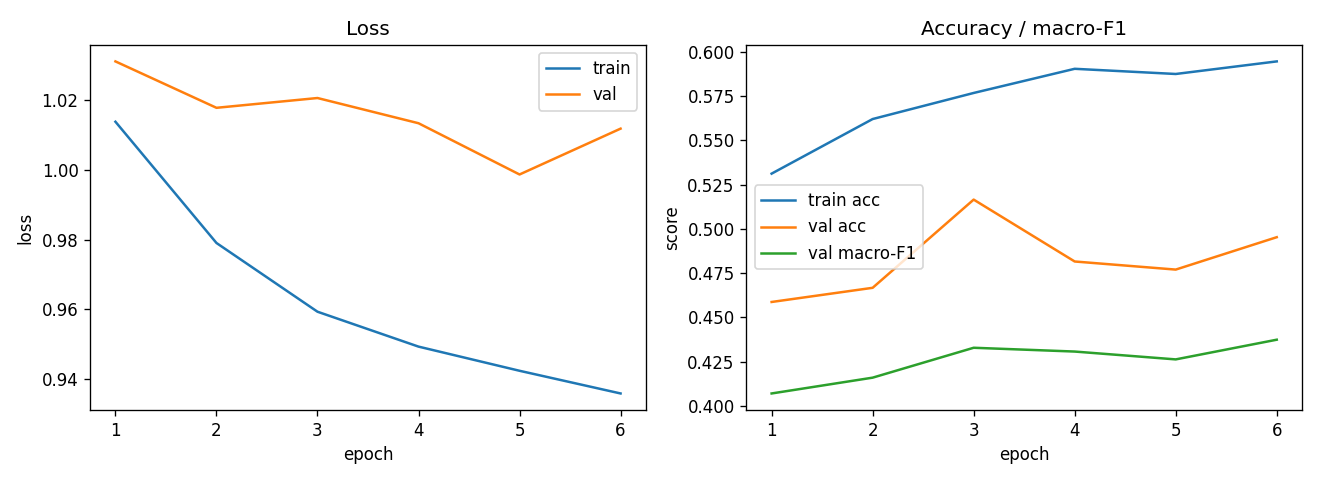

In [3]:
curve = Path(rec["curves"])
if curve.exists():
    display(Image(filename=str(curve)))
else:
    print("curve PNG missing:", curve)
